Exercitiul 1

In [ ]:
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

with pm.Model() as model:

    N = pm.DiscreteUniform("N", lower=20, upper=200)

    Y = pm.HyperGeometric(
        "Y",
        N=N,
        k=20,
        n=15,
        observed=4
    )

    trace = pm.sample(
        2000,
        tune=1000,
        chains=4,
        random_seed=42
    )

Output()

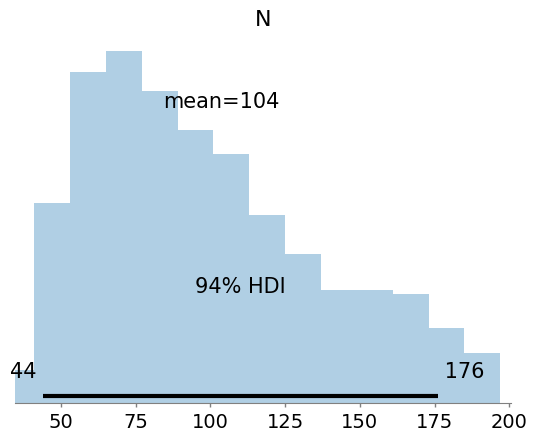

In [ ]:
az.plot_posterior(trace, var_names=["N"])
plt.show()

In [ ]:
import numpy as np
import arviz as az

samples = trace.posterior["N"].values.flatten()

mean_N = np.mean(samples)
median_N = np.median(samples)
hdi_N = az.hdi(samples, hdi_prob=0.95)

N_clasic = 20 * 15 / 4

print("Media posterior:", mean_N)
print("Mediana posterior:", median_N)
print("HDI 95%:", hdi_N)
print("Estimarea clasica Mn/Y:", N_clasic)

Media posterior: 103.73725
Mediana posterior: 97.0
HDI 95%: [ 45 181]
Estimarea clasica Mn/Y: 75.0


Media posterior a dimensiunii populației este 103.73725 iar media a posteriori cu estimarea clasica este de 75. Cele două estimări diferă deoarece metoda Bayesiană ține cont atât de datele observate, cât și de distribuția prioră asupra dimensiunii populației.

In [ ]:
prob = np.mean(samples > 100)

print("P(N > 100 | Y = 4):", prob)

P(N > 100 | Y = 4): 0.465


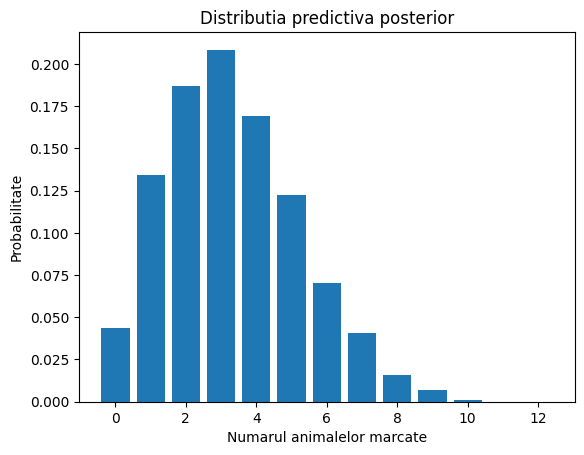

In [ ]:
np.random.seed(42)

y_new = np.array([
    np.random.hypergeometric(20, int(N_i) - 20, 15)
    for N_i in samples
])

values, counts = np.unique(y_new, return_counts=True)
probabilities = counts / len(y_new)

plt.bar(values, probabilities)
plt.xlabel("Numarul animalelor marcate")
plt.ylabel("Probabilitate")
plt.title("Distributia predictiva posterior")
plt.show()

Exercitiul 2

In [ ]:
import pymc as pm
import arviz as az
import numpy as np
import matplotlib.pyplot as plt

A = [3.2, 4.1, 2.8, 5.0, 3.7, 4.5, 3.0, 3.9]
B = [2.1, 2.8, 3.4, 2.5, 3.0, 2.2, 3.6, 2.7]

with pm.Model() as model:
    lambda_A = pm.Gamma("lambda_A", alpha=2, beta=4)
    lambda_B = pm.Gamma("lambda_B", alpha=2, beta=4)

    X_A = pm.Exponential("X_A", lam=lambda_A, observed=A)
    X_B = pm.Exponential("X_B", lam=lambda_B, observed=B)

    trace = pm.sample(2000, tune=1000, chains=4, random_seed=42)

Output()

HDI A: [1.71518126 6.40172522]
HDI B: [1.32930873 4.95377974]


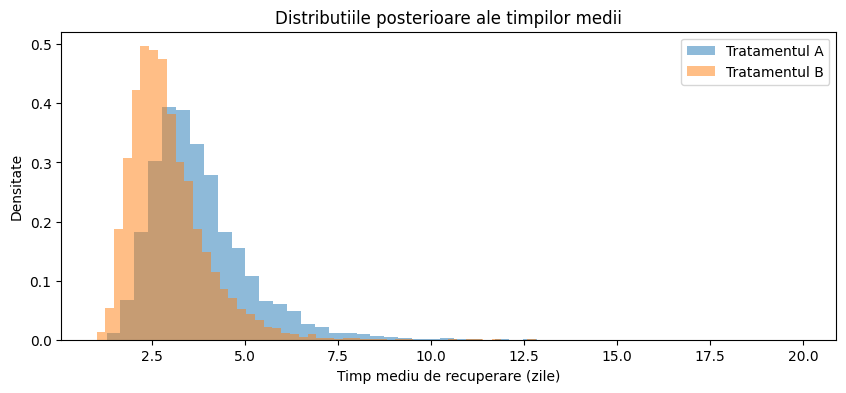

In [ ]:
lambda_A_samples = trace.posterior["lambda_A"].values.flatten()
lambda_B_samples = trace.posterior["lambda_B"].values.flatten()

mean_A = 1 / lambda_A_samples
mean_B = 1 / lambda_B_samples

hdi_A = az.hdi(mean_A, hdi_prob=0.95)
hdi_B = az.hdi(mean_B, hdi_prob=0.95)

print("HDI A:", hdi_A)
print("HDI B:", hdi_B)

plt.figure(figsize=(10, 4))

plt.hist(mean_A, bins=50, density=True, alpha=0.5, label="Tratamentul A")
plt.hist(mean_B, bins=50, density=True, alpha=0.5, label="Tratamentul B")

plt.xlabel("Timp mediu de recuperare (zile)")
plt.ylabel("Densitate")
plt.title("Distributiile posterioare ale timpilor medii")
plt.legend()
plt.show()

In [ ]:
prob_C = np.mean(mean_B < mean_A)

print(prob_C)

0.711


In [ ]:
np.random.seed(42)

patient_A = np.random.exponential(scale=1/lambda_A_samples)
patient_B = np.random.exponential(scale=1/lambda_B_samples)

prob_D = np.mean(patient_B < patient_A)

print(prob_D)

0.552


Exercitiul 3

In [ ]:
Y = [3, 4, 2, 5, 3, 4, 3, 2, 4, 3,
     4, 5, 5, 6, 5, 7, 6, 8, 7, 9,
     8, 10, 9, 8, 11, 9, 10, 8, 9, 10]

t = np.arange(1, 31)

with pm.Model() as model:

    lambda_1 = pm.Exponential("lambda_1", lam=0.2)
    lambda_2 = pm.Exponential("lambda_2", lam=0.2)

    tau = pm.Uniform("tau", lower=1, upper=30)
    k = pm.Exponential("k", lam=1)

    lambda_t = lambda_1 + (lambda_2 - lambda_1) * pm.math.sigmoid(k * (t - tau))

    Y_obs = pm.Poisson("Y_obs", mu=lambda_t, observed=Y)

    trace = pm.sample(2000, tune=1000, chains=4, random_seed=42, target_accept=0.95)

Output()

HDI tau: [ 9.54283844 24.03194363]
HDI k: [0.05493788 1.75873839]


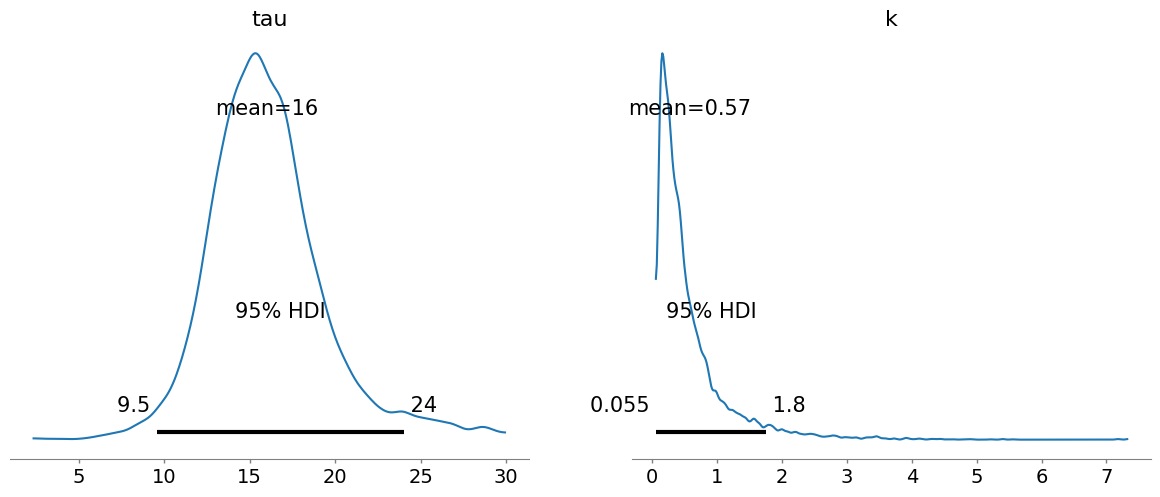

In [ ]:
tau_samples = trace.posterior["tau"].values.flatten()
k_samples = trace.posterior["k"].values.flatten()

hdi_tau = az.hdi(tau_samples, hdi_prob=0.95)
hdi_k = az.hdi(k_samples, hdi_prob=0.95)

print("HDI tau:", hdi_tau)
print("HDI k:", hdi_k)

az.plot_posterior(trace, var_names=["tau", "k"], hdi_prob=0.95)
plt.show()

In [ ]:
lambda_1_samples = trace.posterior["lambda_1"].values.flatten()
lambda_2_samples = trace.posterior["lambda_2"].values.flatten()

prob_C = np.mean(lambda_2_samples > lambda_1_samples)

print(prob_C)

1.0


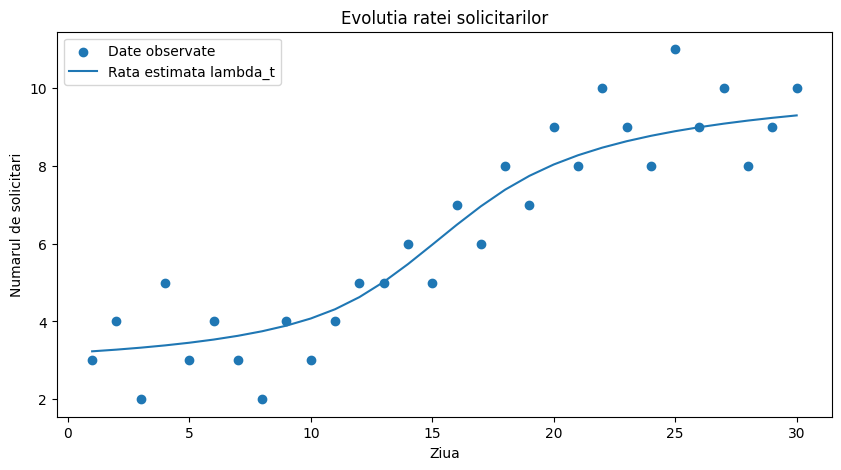

In [ ]:
lambda_est = lambda_1_samples[:, None] + (
    lambda_2_samples[:, None] - lambda_1_samples[:, None]
) * (
    1 / (1 + np.exp(-k_samples[:, None] * (t - tau_samples[:, None])))
)

lambda_mean = np.mean(lambda_est, axis=0)

plt.figure(figsize=(10, 5))

plt.scatter(t, Y, label="Date observate")
plt.plot(t, lambda_mean, label="Rata estimata lambda_t")

plt.xlabel("Ziua")
plt.ylabel("Numarul de solicitari")
plt.title("Evolutia ratei solicitarilor")
plt.legend()
plt.show()

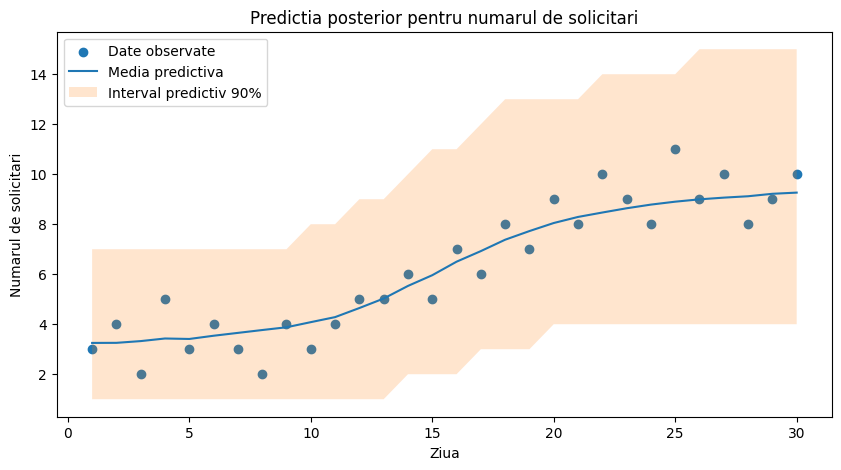

In [ ]:
np.random.seed(42)

Y_pred = np.random.poisson(lam=lambda_est)

Y_pred_mean = np.mean(Y_pred, axis=0)
Y_pred_lower = np.percentile(Y_pred, 5, axis=0)
Y_pred_upper = np.percentile(Y_pred, 95, axis=0)

plt.figure(figsize=(10, 5))

plt.scatter(t, Y, label="Date observate")
plt.plot(t, Y_pred_mean, label="Media predictiva")
plt.fill_between(t, Y_pred_lower, Y_pred_upper, alpha=0.2, label="Interval predictiv 90%")

plt.xlabel("Ziua")
plt.ylabel("Numarul de solicitari")
plt.title("Predictia posterior pentru numarul de solicitari")
plt.legend()
plt.show()